# Aplicación 5 — Reinforcement Learning: equilibrar un péndulo invertido (CartPole)

**Objetivo:** entrenar un agente que aprende **por prueba y error** a mantener un palo en equilibrio sobre un
carrito, usando *policy gradients* (REINFORCE con *baseline*) en PyTorch.

A diferencia del aprendizaje supervisado, aquí **nadie le dice al agente cuál es la acción correcta**. Sólo recibe
una **recompensa** (+1 por cada paso que el palo sigue en pie) y debe descubrir qué secuencia de acciones la
maximiza. Este paradigma está detrás de AlphaGo, el control de robots, la optimización de plasmas en reactores de
fusión y el ajuste fino de modelos de lenguaje con retroalimentación humana (RLHF).

**Contenido**
1. El problema como un proceso de decisión de Markov (MDP).
2. El entorno CartPole implementado desde cero (mismas ecuaciones que `gymnasium`).
3. Una política estocástica como red neuronal.
4. El algoritmo REINFORCE con *baseline* (actor-crítico de Monte Carlo).
5. Evaluación y visualización del agente entrenado.

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

torch.manual_seed(0)
np.random.seed(0)
# Redes diminutas + un paso a la vez: la CPU es más rápida que la GPU aquí
device = "cpu"

## 1. El problema: un MDP

En cada paso $t$ el agente:
1. Observa el **estado** $s_t = (x, \dot x, \theta, \dot\theta)$: posición y velocidad del carrito, ángulo y
   velocidad angular del palo.
2. Elige una **acción** $a_t \in \{\text{izquierda}, \text{derecha}\}$ (empujar con 10 N).
3. Recibe una **recompensa** $r_t = 1$ y el siguiente estado.

El episodio termina si el palo se inclina más de 12°, si el carrito sale de la pista ($|x| > 2.4$ m) o al llegar a
500 pasos (éxito). El objetivo es maximizar el **retorno**: $G = \sum_t \gamma^t r_t$.

## 2. El entorno, desde cero

Implementamos la física con integración de Euler, idéntica a `gymnasium.make("CartPole-v1")`. Escribirlo nosotros
mismos deja claro que un "entorno" es sólo una función `step(acción) → (estado, recompensa, terminado)`.

In [2]:
class CartPole:
    gravity, m_cart, m_pole, half_len, force_mag, tau = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    theta_limit, x_limit, max_steps = 12 * 2 * math.pi / 360, 2.4, 500

    def __init__(self, seed=None):
        self.rng = np.random.default_rng(seed)

    def reset(self):
        self.state = self.rng.uniform(-0.05, 0.05, size=4)
        self.steps = 0
        return self.state.copy()

    def step(self, action):
        x, x_dot, theta, theta_dot = self.state
        force = self.force_mag if action == 1 else -self.force_mag
        total_mass = self.m_cart + self.m_pole
        pml = self.m_pole * self.half_len
        cos, sin = math.cos(theta), math.sin(theta)
        temp = (force + pml * theta_dot ** 2 * sin) / total_mass
        theta_acc = (self.gravity * sin - cos * temp) / (
            self.half_len * (4.0 / 3.0 - self.m_pole * cos ** 2 / total_mass))
        x_acc = temp - pml * theta_acc * cos / total_mass
        x, x_dot = x + self.tau * x_dot, x_dot + self.tau * x_acc
        theta, theta_dot = theta + self.tau * theta_dot, theta_dot + self.tau * theta_acc
        self.state = np.array([x, x_dot, theta, theta_dot])
        self.steps += 1
        fallen = abs(x) > self.x_limit or abs(theta) > self.theta_limit
        done = fallen or self.steps >= self.max_steps
        return self.state.copy(), 1.0, done

env = CartPole(seed=0)
s = env.reset()
print("estado inicial:", np.round(s, 3))

estado inicial: [ 0.014 -0.023 -0.046 -0.048]


### Línea base: un agente aleatorio

In [3]:
def run_episode(env, policy_fn):
    s, total, done, trajectory = env.reset(), 0.0, False, []
    while not done:
        a = policy_fn(s)
        trajectory.append(s)
        s, r, done = env.step(a)
        total += r
    return total, np.array(trajectory)

random_scores = [run_episode(env, lambda s: np.random.randint(2))[0] for _ in range(100)]
print(f"Agente aleatorio: {np.mean(random_scores):.1f} ± {np.std(random_scores):.1f} pasos (máximo posible: 500)")

Agente aleatorio: 23.2 ± 11.9 pasos (máximo posible: 500)


## 3. La política como red neuronal

La red recibe el estado y devuelve una **distribución de probabilidad** sobre las acciones,
$\pi_\theta(a \mid s)$. Durante el entrenamiento muestreamos de ella (exploración); al evaluar podemos tomar la
acción más probable.

También entrenamos un **crítico** $V_\phi(s)$ que estima el retorno esperado desde cada estado. Lo usaremos como
*baseline* para reducir la varianza del gradiente.

In [4]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=128):
        super().__init__()
        self.actor = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(), nn.Linear(hidden, n_actions))
        self.critic = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(), nn.Linear(hidden, 1))

    def forward(self, s):
        return torch.distributions.Categorical(logits=self.actor(s)), self.critic(s).squeeze(-1)

agent = ActorCritic().to(device)
dist, value = agent(torch.tensor(s, dtype=torch.float32))
print("probabilidades iniciales:", dist.probs.detach().numpy(), "| V(s) =", value.item())

probabilidades iniciales: [0.5124944 0.4875056] | V(s) = -0.014265473932027817


## 4. REINFORCE con *baseline*

El **teorema del gradiente de la política** dice que

$$\nabla_\theta J(\theta) = \mathbb{E}\Big[\sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t)\,\big(G_t - V_\phi(s_t)\big)\Big],
\qquad G_t = \sum_{k \ge t} \gamma^{k-t} r_k .$$

Intuición: si una acción llevó a un retorno **mejor de lo esperado** ($G_t - V(s_t) > 0$, la *ventaja*), subimos
su probabilidad; si fue peor, la bajamos. Restar $V(s_t)$ no cambia el valor esperado del gradiente pero reduce
mucho su varianza.

Algoritmo, por cada episodio:
1. Jugar un episodio completo con la política actual, guardando $\log \pi(a_t|s_t)$, $V(s_t)$ y $r_t$.
2. Calcular los retornos $G_t$ hacia atrás.
3. Pérdida del actor: $-\sum_t \log\pi(a_t|s_t)\,\hat A_t$ (ventajas normalizadas). Pérdida del crítico: MSE entre
   $V(s_t)$ y $G_t$. Un pequeño bono de **entropía** evita que la política se vuelva determinista demasiado pronto.

In [5]:
def discounted_returns(rewards, gamma):
    G, out = 0.0, []
    for r in reversed(rewards):
        G = r + gamma * G
        out.append(G)
    return torch.tensor(out[::-1], dtype=torch.float32)

def train(agent, env, episodes=1500, gamma=0.99, lr=3e-3, entropy_coef=0.01, solved=475, window=20):
    opt = torch.optim.Adam(agent.parameters(), lr=lr)
    scores = []
    for ep in range(episodes):
        s, done = env.reset(), False
        log_probs, values, rewards, entropies = [], [], [], []
        while not done:
            dist, v = agent(torch.tensor(s, dtype=torch.float32))
            a = dist.sample()
            s, r, done = env.step(a.item())
            log_probs.append(dist.log_prob(a)); values.append(v)
            rewards.append(r); entropies.append(dist.entropy())

        returns = discounted_returns(rewards, gamma)
        values = torch.stack(values)
        advantages = returns - values.detach()
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        actor_loss = -(torch.stack(log_probs) * advantages).mean()
        critic_loss = F.smooth_l1_loss(values, returns)
        loss = actor_loss + critic_loss - entropy_coef * torch.stack(entropies).mean()
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(agent.actor.parameters(), 1.0)    # recortamos por separado para que el
        nn.utils.clip_grad_norm_(agent.critic.parameters(), 1.0)   # crítico no domine la norma del actor
        opt.step()

        scores.append(sum(rewards))
        avg = np.mean(scores[-window:])
        if (ep + 1) % 50 == 0:
            print(f"episodio {ep + 1:4d} | puntaje {scores[-1]:5.0f} | promedio últimos {window}: {avg:6.1f}")
        if len(scores) >= window and avg >= solved:
            print(f"¡Resuelto en el episodio {ep + 1}! promedio últimos {window} = {avg:.1f}")
            break
    return scores

torch.manual_seed(0)
agent = ActorCritic().to(device)
scores = train(agent, CartPole(seed=1))

episodio   50 | puntaje    11 | promedio últimos 20:   11.8


episodio  100 | puntaje    36 | promedio últimos 20:   34.2


episodio  150 | puntaje    51 | promedio últimos 20:   41.5


episodio  200 | puntaje   140 | promedio últimos 20:  162.1


episodio  250 | puntaje   275 | promedio últimos 20:  280.4


episodio  300 | puntaje   363 | promedio últimos 20:  388.4


episodio  350 | puntaje   169 | promedio últimos 20:  126.9


¡Resuelto en el episodio 390! promedio últimos 20 = 479.7


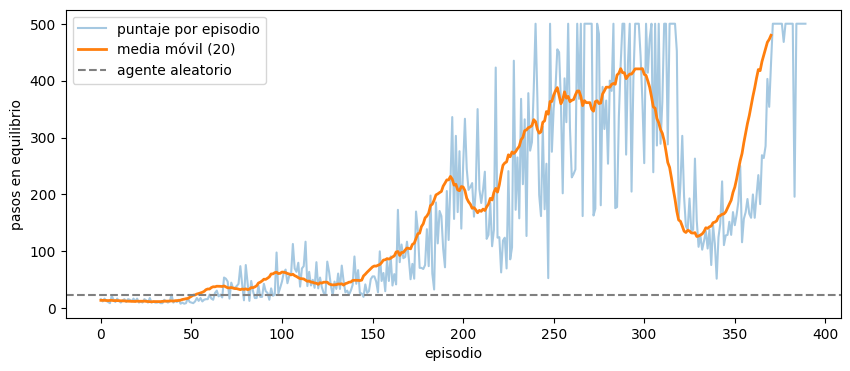

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(scores, alpha=0.4, label="puntaje por episodio")
plt.plot(np.convolve(scores, np.ones(20) / 20, mode="valid"), lw=2, label="media móvil (20)")
plt.axhline(np.mean(random_scores), color="gray", ls="--", label="agente aleatorio")
plt.xlabel("episodio"); plt.ylabel("pasos en equilibrio"); plt.legend(); plt.show()

La curva de aprendizaje en RL suele ser **ruidosa y no monótona**: la política puede mejorar, empeorar
bruscamente y recuperarse. Por eso es buena práctica entrenar con varias semillas y reportar el promedio.

## 5. Evaluación del agente entrenado

Evaluamos con la acción más probable (política *greedy*) en 100 episodios con condiciones iniciales nuevas.

In [7]:
def greedy(s):
    with torch.no_grad():
        dist, _ = agent(torch.tensor(s, dtype=torch.float32))
    return dist.probs.argmax().item()

eval_env = CartPole(seed=123)
eval_scores = [run_episode(eval_env, greedy)[0] for _ in range(100)]
print(f"Agente entrenado: {np.mean(eval_scores):.1f} ± {np.std(eval_scores):.1f} pasos")
print(f"Agente aleatorio: {np.mean(random_scores):.1f} ± {np.std(random_scores):.1f} pasos")

Agente entrenado: 500.0 ± 0.0 pasos
Agente aleatorio: 23.2 ± 11.9 pasos


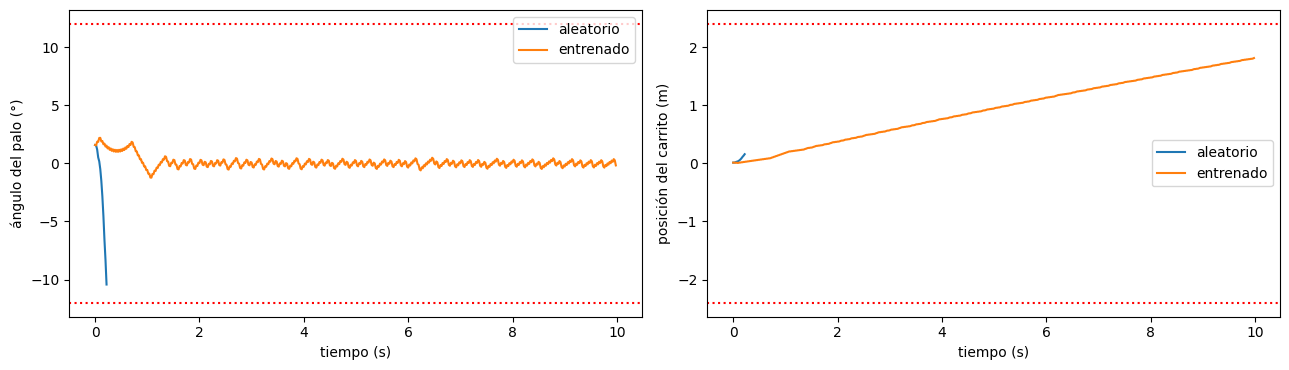

In [8]:
_, traj_rand = run_episode(CartPole(seed=7), lambda s: np.random.randint(2))
_, traj_agent = run_episode(CartPole(seed=7), greedy)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for traj, name in [(traj_rand, "aleatorio"), (traj_agent, "entrenado")]:
    t = np.arange(len(traj)) * CartPole.tau
    ax[0].plot(t, np.degrees(traj[:, 2]), label=name)
    ax[1].plot(t, traj[:, 0], label=name)
for a, lim, lab in [(ax[0], 12, "ángulo del palo (°)"), (ax[1], 2.4, "posición del carrito (m)")]:
    a.axhline(lim, color="r", ls=":"); a.axhline(-lim, color="r", ls=":")
    a.set_ylabel(lab); a.set_xlabel("tiempo (s)"); a.legend()
plt.tight_layout(); plt.show()

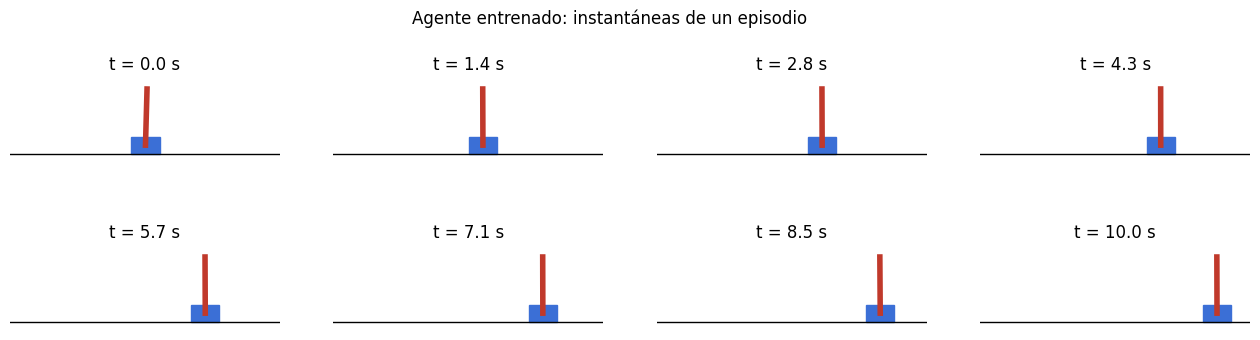

In [9]:
def draw_cartpole(ax, state):
    x, _, theta, _ = state
    ax.add_patch(Rectangle((x - 0.25, -0.15), 0.5, 0.3, color="#3b6fd6"))
    L = 2 * CartPole.half_len
    ax.plot([x, x + L * math.sin(theta)], [0.0, L * math.cos(theta)], color="#c0392b", lw=4)
    ax.axhline(-0.15, color="k", lw=1)
    ax.set_xlim(-2.4, 2.4); ax.set_ylim(-0.3, 1.2); ax.set_aspect("equal"); ax.axis("off")

frames = np.linspace(0, len(traj_agent) - 1, 8).astype(int)
fig, axes = plt.subplots(2, 4, figsize=(16, 4))
for ax, k in zip(axes.ravel(), frames):
    draw_cartpole(ax, traj_agent[k])
    ax.set_title(f"t = {k * CartPole.tau:.1f} s")
plt.suptitle("Agente entrenado: instantáneas de un episodio")
plt.show()

### ¿Qué aprendió la política?

Fijamos $\dot x = \dot\theta = 0$ y dibujamos la probabilidad de empujar a la derecha según la posición y el ángulo.
Esperamos que empuje hacia el lado al que se inclina el palo (como cuando equilibras una escoba en la mano).

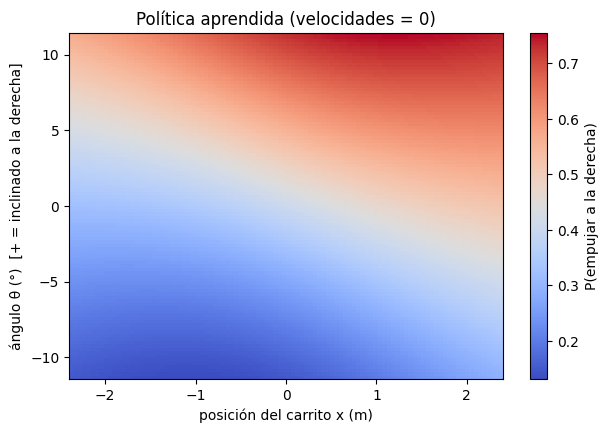

In [10]:
xs = np.linspace(-2.4, 2.4, 100)
thetas = np.linspace(-0.2, 0.2, 100)
grid = torch.tensor([[x, 0.0, th, 0.0] for th in thetas for x in xs], dtype=torch.float32)
with torch.no_grad():
    p_right = agent(grid)[0].probs[:, 1].reshape(100, 100).numpy()

plt.figure(figsize=(7, 4.5))
plt.imshow(p_right, origin="lower", aspect="auto", cmap="coolwarm",
           extent=[xs[0], xs[-1], np.degrees(thetas[0]), np.degrees(thetas[-1])])
plt.colorbar(label="P(empujar a la derecha)")
plt.xlabel("posición del carrito x (m)"); plt.ylabel("ángulo θ (°)  [+ = inclinado a la derecha]")
plt.title("Política aprendida (velocidades = 0)"); plt.show()

## 6. Siguientes pasos

- **Entornos estándar:** `pip install gymnasium` y reemplaza `CartPole()` por `gym.make("CartPole-v1")`
  (la interfaz `reset`/`step` es casi la misma). Prueba `LunarLander-v3` o `Acrobot-v1`.
- **Algoritmos más modernos:**
  - **DQN** (Mnih et al., 2015): aprende $Q(s, a)$ con *replay buffer* y red objetivo; jugó Atari a nivel humano.
  - **PPO** (Schulman et al., 2017): actor-crítico con actualizaciones "recortadas"; es el estándar de facto y el
    algoritmo usado en RLHF.
  - **SAC**: para acciones continuas (robótica).
- **Librerías:** Stable-Baselines3, CleanRL (implementaciones de un solo archivo, ideales para estudiar), TorchRL.

**Ejercicios**
1. Quita el *baseline* (usa $G_t$ en lugar de $G_t - V(s_t)$). ¿Cuántos episodios más necesita? ¿Es más ruidosa?
2. Cambia $\gamma$ a 0.9 y 0.999. ¿Qué pasa con el horizonte que el agente "ve"?
3. Agrega ruido a las observaciones o una fuerza de viento aleatoria. ¿Es robusta la política?
4. Implementa DQN para el mismo entorno y compara la eficiencia en número de episodios.